# 04 · Análise: solução do problema

**MVP — Onde subsidiar o frete no e-commerce brasileiro: pipeline de dados em nuvem (Databricks)**

Universidade de Brasília (UnB) · Departamento de Engenharia de Produção · Sistemas de Suporte à Decisão
Prof. André Luiz Marques Serrano · **Aluna: Brunna Gavião Moraes — 231025341**


**Decisão a apoiar:** onde subsidiar ou renegociar o frete (estados e categorias) e quanto isso custaria.

| # | Pergunta | Hipótese e critério (definidos **antes** da análise) |
|---|---|---|
| P1 | Quanto o frete representa do valor dos pedidos e como evoluiu mês a mês? | Descritiva (linha de base) |
| P2 | Em quais UFs de destino o frete relativo é mais alto, e quanto disso a distância e o peso explicam? | **H2:** entre UFs com ≥ 300 itens, mediana do frete relativo da mais cara ≥ **2×** a da mais barata |
| P3 | Quais categorias têm frete desproporcional ao preço? | **H3:** ≥ **5 categorias** (com ≥ 500 itens) com mediana do frete relativo ≥ **30%** |
| P4 | As UFs com frete mais caro compram menos por habitante? | **H4:** correlação de Spearman entre frete relativo mediano e pedidos por 100 mil hab. **negativa**, p < 0,05 |
| P5 | Quanto custaria subsidiar o frete que excede 30% do preço nas UFs prioritárias? | **H5:** custo ≤ **2%** da receita de produtos da plataforma no período |

**Definições.**
* **Frete relativo** = frete do item ÷ preço do item.
* **UFs prioritárias** = UFs cuja mediana de frete relativo supera a mediana nacional. A regra foi fixada antes da
  análise.

Todas as respostas partem de **consultas SQL sobre a camada gold**. O Python entra só nos testes estatísticos e nos
gráficos.

In [0]:
%pip install -q kagglehub statsmodels

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Configuração comum: localiza o repositório, importa o módulo de apoio e detecta a plataforma.
# No Databricks a variável `spark` já existe; fora dele o mesmo código roda localmente (Parquet + DuckDB).
import os, sys, importlib
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
import mvp_frete as mvp
importlib.reload(mvp)

import pandas as pd
pd.set_option("display.max_columns", 50, "display.width", 200)

plat = mvp.Plataforma(spark if "spark" in globals() else None)
print("Ambiente :", plat.preparar())
print("Bronze   :", plat.dir_bronze)
print("Evidências:", plat.dir_evidencias)

Ambiente : Databricks — catálogo workspace, schemas frete_bronze, frete_silver, frete_gold
Bronze   : /Volumes/workspace/frete_bronze/arquivos
Evidências: /Workspace/Users/brunnagmoraes17@gmail.com/MVP3-SSD-Frete-Olist/evidencias


In [0]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

plat.usar_gold()
COR_REGIAO = {"Norte": "#2a78d6", "Nordeste": "#eb6834", "Centro-Oeste": "#1baf7a", "Sudeste": "#eda100", "Sul": "#e87ba4"}
AZUL, CINZA, TINTA, TINTA2 = "#2a78d6", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": CINZA,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 10,
                     "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.axisbelow": True})

def consulta(nome, q):
    """Executa o SQL na gold, guarda o SQL em scripts/sql e o resultado em evidencias/tabelas."""
    df = plat.sql(q)
    mvp.salvar_sql(q, nome); mvp.salvar_tabela_evidencia(df, plat, nome)
    return df

pct = lambda x, c=1: mvp.fmt_pct(x, c)

## P1 — Quanto o frete pesa e como evoluiu

In [0]:
p1 = consulta("p1_frete_mensal", '''
SELECT t.ano_mes,
       COUNT(*)                                   AS itens,
       SUM(f.preco)                               AS receita_produtos,
       SUM(f.frete)                               AS frete_total,
       SUM(f.frete) / SUM(f.preco)                AS frete_sobre_receita,
       MEDIAN(f.frete_relativo)                   AS mediana_frete_relativo,
       AVG(CASE WHEN f.frete_relativo > 0.30 THEN 1.0 ELSE 0.0 END) AS pct_itens_frete_acima_30
FROM fato_item_frete f
JOIN dim_tempo t ON f.data_compra_sk = t.data_sk
GROUP BY t.ano_mes
ORDER BY t.ano_mes
''')
p1_total = consulta("p1_frete_total", '''
SELECT COUNT(*) AS itens, COUNT(DISTINCT pedido_id) AS pedidos,
       SUM(preco) AS receita_produtos, SUM(frete) AS frete_total,
       SUM(frete) / SUM(preco) AS frete_sobre_receita,
       MEDIAN(frete_relativo) AS mediana_frete_relativo,
       AVG(CASE WHEN frete_relativo > 0.30 THEN 1.0 ELSE 0.0 END) AS pct_itens_frete_acima_30,
       AVG(CASE WHEN frete_relativo > 1.00 THEN 1.0 ELSE 0.0 END) AS pct_itens_frete_acima_preco,
       AVG(CASE WHEN frete_gratis THEN 1.0 ELSE 0.0 END) AS pct_frete_gratis
FROM fato_item_frete
''')
display(p1_total); display(p1)

itens,pedidos,receita_produtos,frete_total,frete_sobre_receita,mediana_frete_relativo,pct_itens_frete_acima_30,pct_itens_frete_acima_preco,pct_frete_gratis
111752,97905,1.3449529679999433E7,2234177.059999879,0.1661156273235551,0.2316066168956853,0.36583,0.03666,0.00343


ano_mes,itens,receita_produtos,frete_total,frete_sobre_receita,mediana_frete_relativo,pct_itens_frete_acima_30
2017-01,953,120098.26999999999,16845.19000000002,0.1402617206725794,0.2252816020025031,0.37566
2017-02,1936,244959.349999995,38602.339999999895,0.15758671795953363,0.24129429892141754,0.38533
2017-03,2975,368341.3200000011,57276.639999999614,0.1554988183242636,0.24105131414267836,0.38319
2017-04,2660,353842.9800000007,52005.62999999965,0.1469737508993383,0.22628497179115736,0.35752
2017-05,4106,503159.190000009,79551.63999999988,0.1581043168465202,0.22307917632486918,0.36751
2017-06,3571,429916.60999999335,69735.62999999967,0.16220734062822265,0.23775100401606428,0.39093
2017-07,4493,492287.30000001064,86466.4300000003,0.17564221136722077,0.23095599393019725,0.35967
2017-08,4882,568245.7900000154,93657.73000000024,0.16481904775748132,0.22912041788373988,0.35805
2017-09,4815,621415.9099999937,95686.80999999939,0.1539819120498546,0.22437395659432388,0.33624
2017-10,5300,660179.6200000156,104576.41000000079,0.15840599562888402,0.23247496423462086,0.35094


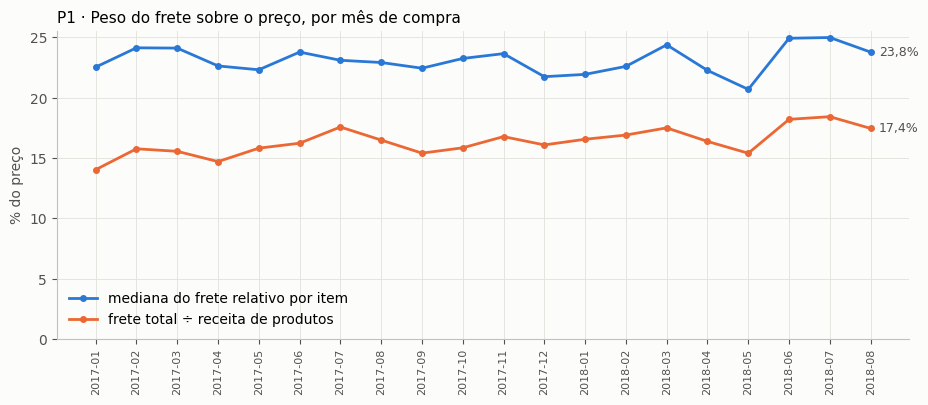

Frete = 16,6% da receita de produtos · mediana por item 23,2% · 36,6% dos itens com frete > 30% do preço · 3,7% com frete > preço
Tendência da mediana mensal (Spearman com o tempo): rho = 0.06, p = 0.816


In [0]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(p1))
ax.plot(x, 100 * p1.mediana_frete_relativo, color=AZUL, lw=2, marker="o", ms=4, label="mediana do frete relativo por item")
ax.plot(x, 100 * p1.frete_sobre_receita, color="#eb6834", lw=2, marker="o", ms=4, label="frete total ÷ receita de produtos")
ax.set_xticks(x, p1.ano_mes, rotation=90, fontsize=8)
ax.set_ylabel("% do preço"); ax.set_ylim(0, None)
ax.set_title("P1 · Peso do frete sobre o preço, por mês de compra")
ax.legend(frameon=False, loc="lower left")
for serie, cor in [("mediana_frete_relativo", AZUL), ("frete_sobre_receita", "#eb6834")]:
    ax.annotate(pct(p1[serie].iloc[-1]), (x[-1], 100 * p1[serie].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=TINTA2, fontsize=9)
mvp.salvar_figura(fig, plat, "p1_frete_mensal"); plt.show()

r = p1_total.iloc[0]
print(f"Frete = {pct(r.frete_sobre_receita)} da receita de produtos · mediana por item {pct(r.mediana_frete_relativo)} · "
      f"{pct(r.pct_itens_frete_acima_30)} dos itens com frete > 30% do preço · {pct(r.pct_itens_frete_acima_preco)} com frete > preço")
rho_t, p_t = stats.spearmanr(np.arange(len(p1)), p1.mediana_frete_relativo)
print(f"Tendência da mediana mensal (Spearman com o tempo): rho = {rho_t:.2f}, p = {p_t:.3f}")

**Discussão P1.**
* **O frete equivale a 16,6% da receita de produtos** (R$ 2,23 mi de frete sobre R$ 13,4 mi em produtos, em 111.752
  itens). No item típico, a mediana é **23,2%** do preço.
* **Mais de um terço dos itens (36,6%)** paga frete acima de 30% do preço, e **3,7%** pagam frete maior que o próprio
  produto.
* **O peso do frete é estrutural, não sazonal:** a mediana mensal ficou entre 20,7% e 25,0% em todo o período, sem
  tendência (Spearman com o tempo ρ = 0,06; p = 0,82). Nem a Black Friday de nov/2017 mudou o patamar.

Um problema estável não se resolve com ação pontual (campanha); pede uma **política** de frete. As próximas perguntas
mostram onde ela deve atuar.

## P2 — Onde o frete relativo é mais alto e quanto a distância e o peso explicam

In [0]:
p2 = consulta("p2_frete_por_uf", '''
SELECT f.uf_destino AS uf, u.regiao,
       COUNT(*)                      AS itens,
       MEDIAN(f.frete_relativo)      AS mediana_frete_relativo,
       SUM(f.frete) / SUM(f.preco)   AS frete_sobre_receita,
       AVG(f.frete)                  AS frete_medio,
       MEDIAN(f.preco)               AS preco_mediano,
       AVG(f.distancia_km)           AS distancia_media_km,
       AVG(p.peso_taxado_kg)         AS peso_taxado_medio_kg,
       AVG(CASE WHEN f.frete_relativo > 0.30 THEN 1.0 ELSE 0.0 END) AS pct_itens_frete_acima_30
FROM fato_item_frete f
JOIN dim_uf u      ON f.uf_destino = u.uf
JOIN dim_produto p ON f.produto_sk = p.produto_sk
GROUP BY f.uf_destino, u.regiao
ORDER BY mediana_frete_relativo DESC
''')
mediana_nacional = float(p1_total.mediana_frete_relativo.iloc[0])
elegiveis = p2[p2.itens >= 300]
uf_max, uf_min = elegiveis.iloc[0], elegiveis.iloc[-1]
razao_h2 = uf_max.mediana_frete_relativo / uf_min.mediana_frete_relativo
print(f"UFs com ≥ 300 itens: {len(elegiveis)} de {len(p2)}")
print(f"Mais cara: {uf_max.uf} ({pct(uf_max.mediana_frete_relativo)}) · mais barata: {uf_min.uf} "
      f"({pct(uf_min.mediana_frete_relativo)}) · razão = {razao_h2:.2f}×")
display(p2)

UFs com ≥ 300 itens: 22 de 27
Mais cara: MA (39,9%) · mais barata: SP (19,3%) · razão = 2.06×


uf,regiao,itens,mediana_frete_relativo,frete_sobre_receita,frete_medio,preco_mediano,distancia_media_km,peso_taxado_medio_kg,pct_itens_frete_acima_30
AM,Norte,165,0.40982292014700966,0.24506549226098143,33.20539393939394,84.0,2646.1105920086184,2.148237373737374,0.62424
RO,Norte,277,0.4000465170368648,0.24748477351665085,41.12682310469315,95.0,2231.4393297682172,3.204030685920578,0.65704
MA,Nordeste,811,0.39854014598540144,0.2622686768640437,38.349876695437736,89.0,2103.360085115094,2.79616687217427,0.62515
PB,Nordeste,599,0.3674489795918367,0.2231631485348908,42.77884808013356,99.95,2095.50044294269,3.0687723984418476,0.58264
TO,Norte,314,0.36497765867758647,0.2367200122895103,37.24796178343949,89.345,1481.7860687756186,3.476737261146497,0.56051
RR,Norte,48,0.3625595238095238,0.2775549538800422,44.10145833333333,122.99,3248.6819091809575,2.835413194444445,0.64583
AC,Norte,92,0.34843554443053815,0.23066768024676298,40.07336956521739,99.945,2642.3047961821485,2.449128623188406,0.63043
SE,Nordeste,382,0.34835918559918705,0.23963339552556995,36.782722513089006,89.9,1651.2796250747717,3.445102966841186,0.57592
PA,Norte,1073,0.343,0.21641348238643998,35.84709226467849,99.0,2281.602547415634,3.0859913016464744,0.55825
PI,Nordeste,538,0.33294202898550723,0.24371622979224217,39.16224907063197,99.99,1961.822380597686,3.2036977032898823,0.54089


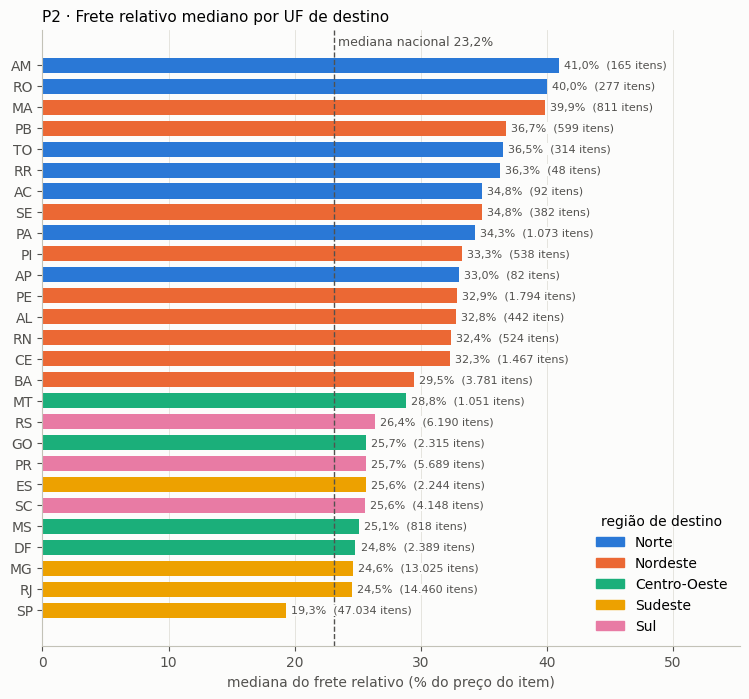

In [0]:
d = p2.sort_values("mediana_frete_relativo")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(d.uf, 100 * d.mediana_frete_relativo, color=[COR_REGIAO[r] for r in d.regiao], height=0.72)
ax.axvline(100 * mediana_nacional, color=TINTA2, lw=1, ls="--")
ax.text(100 * mediana_nacional, len(d) - 0.2, f" mediana nacional {pct(mediana_nacional)}", color=TINTA2, fontsize=9, va="bottom")
for yy, (v, n) in enumerate(zip(d.mediana_frete_relativo, d.itens)):
    ax.text(100 * v + 0.4, yy, f"{pct(v)}  ({mvp.fmt_num(n)} itens)", va="center", fontsize=8, color=TINTA2, bbox=dict(fc="#fcfcfb", ec="none", pad=0.5))
ax.set_xlabel("mediana do frete relativo (% do preço do item)")
ax.set_title("P2 · Frete relativo mediano por UF de destino")
ax.grid(axis="y", visible=False); ax.set_xlim(0, 100 * d.mediana_frete_relativo.max() * 1.35)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COR_REGIAO.values()], labels=list(COR_REGIAO),
          frameon=False, loc="lower right", title="região de destino")
mvp.salvar_figura(fig, plat, "p2_frete_relativo_por_uf"); plt.show()

**Quanto a distância e o peso explicam.** A regressão log-log usa só os itens com frete > 0, distância e peso
conhecidos:

$\ln(\text{frete}) = \beta_0 + \beta_1\ln(\text{peso taxado}) + \beta_2\ln(1+\text{distância}) + \beta_3\ln(\text{preço})$

* Os coeficientes são **elasticidades**: +1% de distância muda o frete em β₂%.
* Em seguida entra a UF de destino. O ganho de R² mostra quanto a UF explica **além** de distância, peso e preço.
* A diferença de frete entre Norte/Nordeste e Sudeste é comparada **antes e depois** do controle por esses fatores.

In [0]:
q_base = '''
SELECT f.frete, f.preco, f.distancia_km, p.peso_taxado_kg, f.uf_destino, u.regiao
FROM fato_item_frete f
JOIN dim_produto p ON f.produto_sk = p.produto_sk
JOIN dim_uf u      ON f.uf_destino = u.uf
WHERE f.frete > 0 AND f.distancia_km IS NOT NULL AND p.peso_taxado_kg > 0
'''
mvp.salvar_sql(q_base, "p2_base_regressao")   # base item a item: só o SQL vai para o repositório
base = plat.sql(q_base)
base = base.astype({"frete": float, "preco": float, "distancia_km": float, "peso_taxado_kg": float})
form = "np.log(frete) ~ np.log(peso_taxado_kg) + np.log1p(distancia_km) + np.log(preco)"
m1 = smf.ols(form, data=base).fit(cov_type="HC1")
m2 = smf.ols(form + " + C(uf_destino)", data=base).fit(cov_type="HC1")
nomes = {"np.log(peso_taxado_kg)": "peso taxado", "np.log1p(distancia_km)": "distância", "np.log(preco)": "preço"}
elast = pd.DataFrame({"fator": [nomes[k] for k in nomes], "elasticidade": [m1.params[k] for k in nomes],
                      "ic95_inf": [m1.conf_int().loc[k, 0] for k in nomes], "ic95_sup": [m1.conf_int().loc[k, 1] for k in nomes],
                      "p_valor": [m1.pvalues[k] for k in nomes]})
mvp.salvar_tabela_evidencia(elast, plat, "p2_elasticidades")
display(elast.round(4))
print(f"n = {int(m1.nobs):,} itens · R² (distância + peso + preço) = {m1.rsquared:.3f} · "
      f"R² com UF de destino = {m2.rsquared:.3f} (ganho {m2.rsquared - m1.rsquared:.3f})".replace(",", "."))

base["ln_frete"], base["pred"] = np.log(base.frete), m1.fittedvalues
nne, se = base.regiao.isin(["Norte", "Nordeste"]), base.regiao == "Sudeste"
gap_bruto = base.ln_frete[nne].mean() - base.ln_frete[se].mean()
gap_explicado = base.pred[nne].mean() - base.pred[se].mean()
part_explicada = gap_explicado / gap_bruto
gap = pd.DataFrame([{"comparacao": "Norte+Nordeste vs Sudeste",
                     "frete_medio_geometrico_nne": np.exp(base.ln_frete[nne].mean()),
                     "frete_medio_geometrico_se": np.exp(base.ln_frete[se].mean()),
                     "diferenca_bruta_pct": np.exp(gap_bruto) - 1,
                     "diferenca_explicada_pct": np.exp(gap_explicado) - 1,
                     "parcela_explicada_dist_peso_preco": part_explicada}])
mvp.salvar_tabela_evidencia(gap, plat, "p2_decomposicao_regional")
display(gap.round(3))

fator,elasticidade,ic95_inf,ic95_sup,p_valor
peso taxado,0.146,0.1435,0.1485,0.0
distância,0.1936,0.1918,0.1954,0.0
preço,0.1344,0.1315,0.1372,0.0


n = 110.803 itens · R² (distância + peso + preço) = 0.495 · R² com UF de destino = 0.528 (ganho 0.033)


comparacao,frete_medio_geometrico_nne,frete_medio_geometrico_se,diferenca_bruta_pct,diferenca_explicada_pct,parcela_explicada_dist_peso_preco
Norte+Nordeste vs Sudeste,28.588,15.117,0.891,0.544,0.682


**Discussão P2.**
* **H2 confirmada, por margem pequena:** entre as 22 UFs com pelo menos 300 itens, o Maranhão (39,9%) tem frete
  relativo **2,06×** o de São Paulo (19,3%).
  * As 15 UFs com frete relativo mais alto são todas do Norte e do Nordeste.
  * AM, RO e RR estão no topo, mas têm menos de 300 itens. Ficaram fora do critério para que uma amostra pequena não
    decidisse a hipótese.
* **Quanto a distância e o peso explicam:**
  * A regressão log-log, com 110.803 itens, explica **49,5%** da variação do frete com três fatores: distância
    (elasticidade 0,19), peso taxado (0,15) e preço (0,13). Os três têm IC 95% estreito e p < 0,001.
  * A UF de destino acrescenta só **3,3 pontos** de R².
  * O frete típico do Norte e Nordeste é **89% maior** que o do Sudeste (média geométrica de R$ 28,59 contra
    R$ 15,12), e **68%** dessa diferença se explica por distância, peso e preço.
* **Leitura para a decisão:** a desigualdade regional é, na maior parte, **geográfica**. O vendedor está no Sudeste e o
  frete cresce com a distância. Os 32% que sobram são o espaço de uma **renegociação com transportadoras** nas rotas
  para o Norte e Nordeste. O resto só se reduz aproximando o estoque do cliente (vendedores ou centros de distribuição
  regionais) ou subsidiando.
* **Limitação:** a distância é em linha reta entre centroides de CEP, não a rota real, e a base não identifica a
  transportadora.

## P3 — Categorias com frete desproporcional ao preço

In [0]:
p3 = consulta("p3_frete_por_categoria", '''
SELECT p.categoria,
       COUNT(*)                     AS itens,
       MEDIAN(f.frete_relativo)     AS mediana_frete_relativo,
       MEDIAN(f.preco)              AS preco_mediano,
       MEDIAN(f.frete)              AS frete_mediano,
       MEDIAN(p.peso_taxado_kg)     AS peso_taxado_mediano_kg,
       AVG(CASE WHEN p.peso_cubado_kg > p.peso_real_kg THEN 1.0 ELSE 0.0 END) AS pct_cubado_maior_que_real,
       AVG(CASE WHEN f.frete_relativo > 0.30 THEN 1.0 ELSE 0.0 END) AS pct_itens_frete_acima_30,
       SUM(f.frete)                 AS frete_total
FROM fato_item_frete f
JOIN dim_produto p ON f.produto_sk = p.produto_sk
GROUP BY p.categoria
HAVING COUNT(*) >= 500
ORDER BY mediana_frete_relativo DESC
''')
cat_h3 = p3[p3.mediana_frete_relativo >= 0.30]
print(f"{len(p3)} categorias com ≥ 500 itens · {len(cat_h3)} com mediana do frete relativo ≥ 30%")
display(p3)

30 categorias com ≥ 500 itens · 3 com mediana do frete relativo ≥ 30%


categoria,itens,mediana_frete_relativo,preco_mediano,frete_mediano,peso_taxado_mediano_kg,pct_cubado_maior_que_real,pct_itens_frete_acima_30,frete_total
eletronicos,2754,0.626984126984127,21.89,15.1,0.6453333333333333,0.80029,0.73929,46325.43
telefonia,4518,0.43246247915508623,29.99,15.1,0.3,0.51903,0.65073,70841.77000000015
eletrodomesticos,769,0.3104089219330855,47.59,16.11,0.9945,0.76203,0.51365,14770.060000000001
ferramentas_jardim,4323,0.294991652754591,59.9,17.67,3.3,0.66759,0.42193,98409.94999999998
utilidades_domesticas,6903,0.29025,59.7,16.74,2.6041666666666665,0.65855,0.47602,144953.8700000001
alimentos,508,0.282078853046595,48.89,12.94,0.75,0.68504,0.38386,7236.940000000002
fashion_bolsas_e_acessorios,2016,0.2774641221057577,49.0,15.1,0.26666666666666666,0.64038,0.45040,31173.610000000004
livros_interesse_geral,545,0.2729093050647821,44.9,15.56,1.0,0.55229,0.44037,9011.36
moveis_decoracao,8229,0.2701168614357262,65.49,16.39,2.3333333333333335,0.61514,0.42885,170853.26
consoles_games,1117,0.2687114519086514,58.0,15.11,0.48,0.84154,0.47449,19505.169999999984


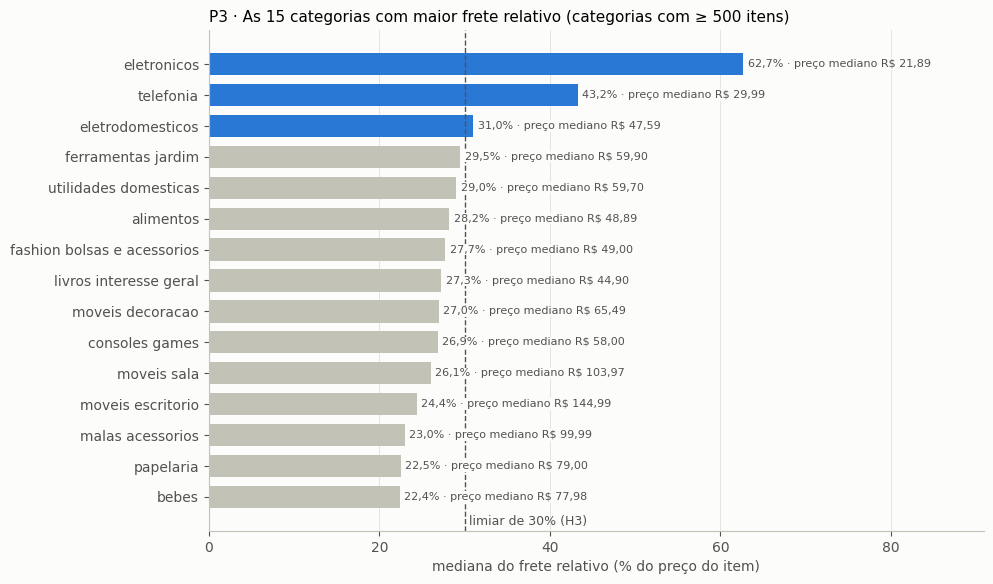

In [0]:
top = p3.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
cores = [AZUL if v >= 0.30 else CINZA for v in top.mediana_frete_relativo]
ax.barh(top.categoria.str.replace("_", " "), 100 * top.mediana_frete_relativo, color=cores, height=0.72)
ax.axvline(30, color=TINTA2, lw=1, ls="--"); ax.text(30.5, -0.9, "limiar de 30% (H3)", color=TINTA2, fontsize=9)
for yy, (v, pm) in enumerate(zip(top.mediana_frete_relativo, top.preco_mediano)):
    ax.text(100 * v + 0.5, yy, f"{pct(v)} · preço mediano R$ {mvp.fmt_num(pm, 2)}", va="center", fontsize=8, color=TINTA2, bbox=dict(fc="#fcfcfb", ec="none", pad=0.5))
ax.set_xlim(0, 100 * top.mediana_frete_relativo.max() * 1.45)
ax.set_xlabel("mediana do frete relativo (% do preço do item)"); ax.grid(axis="y", visible=False)
ax.set_title("P3 · As 15 categorias com maior frete relativo (categorias com ≥ 500 itens)")
mvp.salvar_figura(fig, plat, "p3_frete_por_categoria"); plt.show()

**Complemento: o frete relativo por faixa de preço.** Se o frete quase não acompanha o preço, o frete relativo deve
cair com o preço, em qualquer categoria. A consulta abaixo mostra isso direto.

In [0]:
p3b = consulta("p3_frete_por_faixa_de_preco", '''
SELECT CASE WHEN f.preco <= 30  THEN '1. até R$ 30'
            WHEN f.preco <= 50  THEN '2. R$ 30–50'
            WHEN f.preco <= 100 THEN '3. R$ 50–100'
            WHEN f.preco <= 200 THEN '4. R$ 100–200'
            ELSE                     '5. acima de R$ 200' END AS faixa_preco,
       COUNT(*)                 AS itens,
       MEDIAN(f.frete)          AS frete_mediano,
       MEDIAN(f.frete_relativo) AS mediana_frete_relativo,
       AVG(CASE WHEN f.frete_relativo > 0.30 THEN 1.0 ELSE 0.0 END) AS pct_itens_frete_acima_30
FROM fato_item_frete f
GROUP BY 1
ORDER BY 1
''')
display(p3b)

faixa_preco,itens,frete_mediano,mediana_frete_relativo,pct_itens_frete_acima_30
1. até R$ 30,20130,14.1,0.6224000000000001,0.91674
2. R$ 30–50,18880,15.1,0.3527054108216433,0.67945
3. R$ 50–100,32780,16.18,0.2226528316039505,0.20561
4. R$ 100–200,26759,18.54,0.13560471226375118,0.09174
5. acima de R$ 200,13203,22.9,0.06979131029763941,0.03067


**Discussão P3.**
* **H3 refutada:** só **3 categorias** (de 30 com pelo menos 500 itens) têm frete relativo mediano de 30% ou mais:
  * eletrônicos: 62,7%, com preço mediano de R$ 21,89;
  * telefonia: 43,2%, com R$ 29,99;
  * eletrodomésticos: 31,0%, com R$ 47,59.
* **O que as torna caras não é o peso, é o preço baixo:**
  * O frete mediano é parecido em quase todas as categorias, perto de **R$ 15**. Funciona como um **piso**.
  * Na tabela complementar, o frete relativo cai de **62%** nos itens de até R$ 30 para **7%** nos itens acima de
    R$ 200.
  * Categorias pesadas, como móveis de escritório (13 kg taxados), pagam frete mais alto em reais, mas como o preço
    também é alto, o frete relativo fica em 24%.
* **Leitura para a decisão:** um subsídio **por categoria** acerta pouco. A alavanca é o **piso do frete para itens
  baratos**, com frete grátis acima de um valor mínimo de carrinho, incentivo a kits e agrupamento de itens no mesmo
  envio.
* O peso cubado supera o peso real em 80% dos eletrônicos, o que mostra embalagens grandes para o produto. Revisar a
  embalagem é uma ação barata para essa categoria.

## P4 — Frete mais caro, menos compras por habitante? (Olist × IBGE)

In [0]:
p4 = consulta("p4_pedidos_por_habitante", '''
SELECT u.uf, u.regiao, u.populacao_2018,
       COUNT(DISTINCT f.pedido_id)                                AS pedidos,
       COUNT(DISTINCT f.pedido_id) * 100000.0 / u.populacao_2018  AS pedidos_por_100mil_hab,
       MEDIAN(f.frete_relativo)                                   AS mediana_frete_relativo,
       AVG(f.distancia_km)                                        AS distancia_media_km
FROM dim_uf u
LEFT JOIN fato_item_frete f ON f.uf_destino = u.uf
GROUP BY u.uf, u.regiao, u.populacao_2018
ORDER BY pedidos_por_100mil_hab DESC
''')
rho4, p4v = stats.spearmanr(p4.mediana_frete_relativo, p4.pedidos_por_100mil_hab)
sem_sp = p4[p4.uf != "SP"]
rho4b, p4vb = stats.spearmanr(sem_sp.mediana_frete_relativo, sem_sp.pedidos_por_100mil_hab)
rho4d, p4vd = stats.spearmanr(p4.distancia_media_km, p4.pedidos_por_100mil_hab)
print(f"Spearman (frete relativo × pedidos por 100 mil hab.), 27 UFs: rho = {rho4:.2f}, p = {p4v:.4f}")
print(f"Robustez sem SP: rho = {rho4b:.2f}, p = {p4vb:.4f} · distância média × pedidos/hab.: rho = {rho4d:.2f}, p = {p4vd:.4f}")
display(p4)

Spearman (frete relativo × pedidos por 100 mil hab.), 27 UFs: rho = -0.87, p = 0.0000
Robustez sem SP: rho = -0.85, p = 0.0000 · distância média × pedidos/hab.: rho = -0.94, p = 0.0000


uf,regiao,populacao_2018,pedidos,pedidos_por_100mil_hab,mediana_frete_relativo,distancia_media_km
SP,Sudeste,45538936,41021,90.07896012327,0.1932761087267525,247.54500739741428
RJ,Sudeste,17159960,12654,73.74143063271,0.24536418382354364,487.41618022591007
DF,Centro-Oeste,2974703,2114,71.06591817738,0.2482891735392174,828.670879820168
MG,Sudeste,21040662,11457,54.45170879129,0.2462311557788945,534.0605407182352
SC,Sul,7075494,3590,50.73850673889,0.2555422150391912,573.4137443340921
ES,Sudeste,3972388,2014,50.69998197558,0.2564179104477612,799.8408412420572
RS,Sul,11329605,5395,47.61860629740,0.2635655949364048,868.9260317406813
PR,Sul,11348937,4962,43.72215653325,0.2568,485.95265725822975
GO,Centro-Oeste,6921161,1990,28.75240151183,0.2569565217391304,775.2427370959416
MT,Centro-Oeste,3441998,900,26.14760380453,0.2882051282051282,1352.292415338618


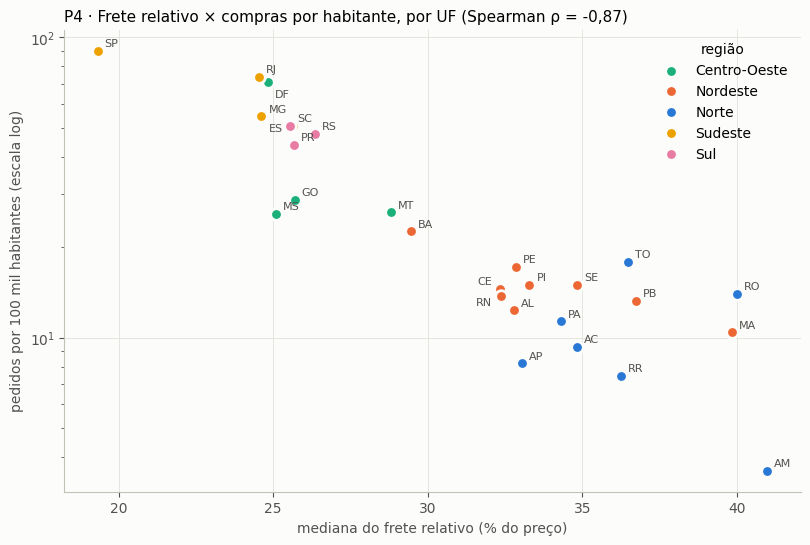

In [0]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for reg, g in p4.groupby("regiao"):
    ax.scatter(100 * g.mediana_frete_relativo, g.pedidos_por_100mil_hab, s=70, color=COR_REGIAO[reg],
               edgecolor="#fcfcfb", linewidth=2, label=reg, zorder=3)
for _, rr in p4.iterrows():
    desloc = {"ES": (-17, -4), "DF": (5, -11), "RN": (-18, -7), "CE": (-16, 3)}.get(rr.uf, (5, 3))
    ax.annotate(rr.uf, (100 * rr.mediana_frete_relativo, rr.pedidos_por_100mil_hab), xytext=desloc,
                textcoords="offset points", fontsize=8, color=TINTA2)
ax.set_yscale("log")
ax.set_xlabel("mediana do frete relativo (% do preço)"); ax.set_ylabel("pedidos por 100 mil habitantes (escala log)")
ax.set_title(f"P4 · Frete relativo × compras por habitante, por UF (Spearman ρ = {rho4:.2f})".replace(".", ","))
ax.legend(frameon=False, title="região")
mvp.salvar_figura(fig, plat, "p4_frete_vs_pedidos_por_habitante"); plt.show()

**Discussão P4.**
* **H4 confirmada pelo critério:** a correlação de Spearman entre o frete relativo mediano e os pedidos por 100 mil
  habitantes é **ρ = −0,87** (p < 0,001; 27 UFs).
  * O resultado se mantém sem São Paulo (ρ = −0,85).
  * São Paulo tem 90 pedidos por 100 mil habitantes; Maranhão, Amapá e Roraima ficam entre 8 e 10.
* **Este é o resultado que exige mais cuidado na leitura.**
  * A **distância média sozinha** tem correlação ainda mais forte com os pedidos por habitante (ρ = −0,94).
  * Renda e acesso à internet, ausentes da base, também caem nas mesmas UFs.
  * Por isso a P4 mostra que **frete caro e baixa penetração andam juntos**, mas não prova que o frete *causa* a baixa
    demanda.
* **Leitura para a decisão:** o subsídio regional é coerente com os dados, mas o tamanho do ganho de vendas só se mede
  com um **experimento controlado**, por exemplo subsidiar em parte das UFs ou dos CEPs e comparar com o restante.

## P5 — Quanto custaria subsidiar o frete acima de 30% do preço

In [0]:
LIMITE = 0.30
p5 = consulta("p5_subsidio_por_uf", f'''
WITH nacional AS (SELECT MEDIAN(frete_relativo) AS m FROM fato_item_frete),
     por_uf   AS (SELECT uf_destino, MEDIAN(frete_relativo) AS m FROM fato_item_frete GROUP BY uf_destino)
SELECT f.uf_destino AS uf, u.regiao,
       COUNT(*)                                                                  AS itens,
       SUM(f.preco)                                                              AS receita_produtos,
       SUM(f.frete)                                                              AS frete_total,
       SUM(CASE WHEN f.frete > {LIMITE} * f.preco THEN 1 ELSE 0 END)             AS itens_beneficiados,
       SUM(CASE WHEN f.frete > {LIMITE} * f.preco THEN f.frete - {LIMITE} * f.preco ELSE 0 END) AS custo_subsidio
FROM fato_item_frete f
JOIN por_uf pu ON f.uf_destino = pu.uf_destino
JOIN dim_uf u  ON f.uf_destino = u.uf
CROSS JOIN nacional n
WHERE pu.m > n.m
GROUP BY f.uf_destino, u.regiao
ORDER BY custo_subsidio DESC
''')
receita_total = float(p1_total.receita_produtos.iloc[0]); frete_total = float(p1_total.frete_total.iloc[0])
meses = p1.ano_mes.nunique()
custo = p5.custo_subsidio.sum()
p5["custo_por_item_beneficiado"] = p5.custo_subsidio / p5.itens_beneficiados
print(f"UFs prioritárias ({len(p5)}): {', '.join(p5.sort_values('uf').uf)}")
print(f"Custo do subsídio em {meses} meses: R$ {mvp.fmt_num(custo, 2)} (R$ {mvp.fmt_num(custo / meses, 2)}/mês) · "
      f"{pct(custo / receita_total, 2)} da receita de produtos · {pct(custo / frete_total)} do frete total · "
      f"{mvp.fmt_num(p5.itens_beneficiados.sum())} itens beneficiados")
display(p5)

UFs prioritárias (26): AC, AL, AM, AP, BA, CE, DF, ES, GO, MA, MG, MS, MT, PA, PB, PE, PI, PR, RJ, RN, RO, RR, RS, SC, SE, TO
Custo do subsídio em 20 meses: R$ 274.913,40 (R$ 13.745,67/mês) · 2,04% da receita de produtos · 12,3% do frete total · 27.825 itens beneficiados


uf,regiao,itens,receita_produtos,frete_total,itens_beneficiados,custo_subsidio,custo_por_item_beneficiado
RJ,Sudeste,14460,1802436.2399999737,303113.3999999991,5578,44800.78000000003,8.031692362854075
MG,Sudeste,13025,1568855.9799999807,268790.0899999993,5123,39038.45300000003,7.620232871364441
RS,Sul,6190,739357.4599999988,134277.30000000005,2584,22425.726000000028,8.67868653250775
BA,Nordeste,3781,506214.7800000007,99698.54000000007,1860,20307.968999999997,10.918262903225806
PR,Sul,5689,674867.5499999998,116834.34000000011,2408,19263.28700000001,7.99970390365449
PE,Nordeste,1794,260370.84000000052,58959.010000000024,977,13836.978999999998,14.162721596724666
SC,Sul,4148,516340.2200000008,89182.76000000011,1714,13693.943000000001,7.9894649941656946
CE,Nordeste,1467,224574.68000000028,47998.150000000016,781,11037.593,14.13264148527529
PA,Norte,1073,177733.52000000016,38463.930000000015,599,9706.651999999998,16.2047612687813
MA,Nordeste,811,118587.35999999994,31101.750000000004,507,9681.478,19.09561735700197


In [0]:
# Sensibilidade: limite do subsídio × abrangência (UFs prioritárias ou todas)
itens = plat.sql("SELECT uf_destino, preco, frete FROM fato_item_frete").astype({"preco": float, "frete": float})
prioritarias = set(p5.uf)
linhas = []
for limite in [0.20, 0.30, 0.40, 0.50]:
    excesso = (itens.frete - limite * itens.preco).clip(lower=0)
    nne = itens.uf_destino.map(lambda u: mvp.UF_INFO[u][2]).isin(["Norte", "Nordeste"])
    for escopo, mask in [("UFs prioritárias", itens.uf_destino.isin(prioritarias)),
                         ("todas as UFs", pd.Series(True, index=itens.index)),
                         ("Norte e Nordeste (exploratório)", nne)]:
        c = excesso[mask].sum()
        linhas.append({"limite_frete_relativo": limite, "escopo": escopo, "custo_total": c, "custo_mensal": c / meses,
                       "pct_receita_produtos": c / receita_total, "itens_beneficiados": int((excesso[mask] > 0).sum())})
sens = pd.DataFrame(linhas)
mvp.salvar_tabela_evidencia(sens, plat, "p5_sensibilidade")
display(sens.assign(pct_receita_produtos=lambda d: d.pct_receita_produtos.map(lambda v: pct(v, 2))))

limite_frete_relativo,escopo,custo_total,custo_mensal,pct_receita_produtos,itens_beneficiados
0.2,UFs prioritárias,470474.964,23523.748199999998,"3,50%",40663
0.2,todas as UFs,612482.432,30624.121600000002,"4,55%",63350
0.2,Norte e Nordeste (exploratório),157949.956,7897.4978,"1,17%",8860
0.3,UFs prioritárias,274913.39900000003,13745.669950000001,"2,04%",27825
0.3,todas as UFs,346174.89800000004,17308.7449,"2,57%",40883
0.3,Norte e Nordeste (exploratório),101400.69200000001,5070.034600000001,"0,75%",6693
0.4,UFs prioritárias,171507.202,8575.3601,"1,28%",18915
0.4,todas as UFs,210826.97799999997,10541.348899999999,"1,57%",27107
0.4,Norte e Nordeste (exploratório),67811.54,3390.5769999999998,"0,50%",4978
0.5,UFs prioritárias,112780.315,5639.0157500000005,"0,84%",13663


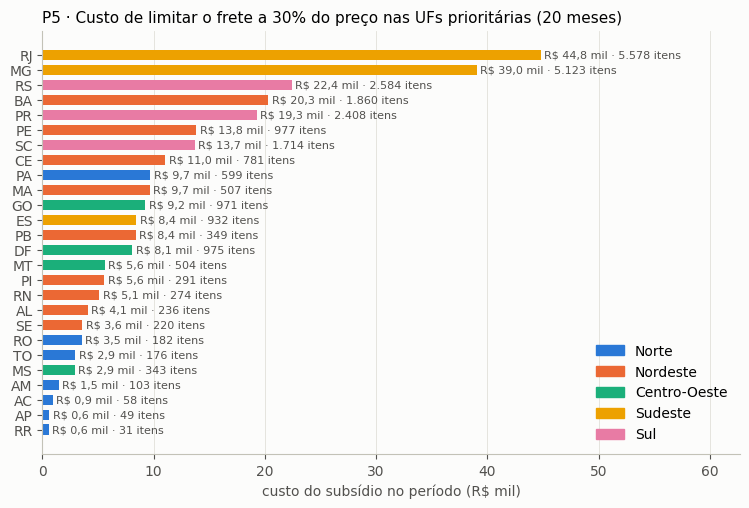

In [0]:
d = p5.sort_values("custo_subsidio")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(d.uf, d.custo_subsidio / 1000, color=[COR_REGIAO[r] for r in d.regiao], height=0.7)
for yy, (v, n) in enumerate(zip(d.custo_subsidio, d.itens_beneficiados)):
    ax.text(v / 1000 + 0.3, yy, f"R$ {mvp.fmt_num(v / 1000, 1)} mil · {mvp.fmt_num(n)} itens", va="center", fontsize=8, color=TINTA2)
ax.set_xlim(0, d.custo_subsidio.max() / 1000 * 1.4); ax.grid(axis="y", visible=False)
ax.set_xlabel("custo do subsídio no período (R$ mil)")
ax.set_title(f"P5 · Custo de limitar o frete a 30% do preço nas UFs prioritárias ({meses} meses)")
present = [r for r in COR_REGIAO if r in set(d.regiao)]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COR_REGIAO[r]) for r in present], labels=present, frameon=False, loc="lower right")
mvp.salvar_figura(fig, plat, "p5_custo_subsidio_por_uf"); plt.show()

**Discussão P5.**
* **H5 refutada, por pouco:** limitar o frete a 30% do preço nas UFs prioritárias custaria **R$ 274,9 mil em 20 meses**
  (R$ 13,7 mil/mês). Isso equivale a **2,04%** da receita de produtos, contra o limite de 2% fixado. O subsídio
  beneficiaria 27.825 itens.
* **A regra de priorização, fixada antes da análise, não foi seletiva:**
  * São Paulo concentra 42% dos itens e puxa a mediana nacional para baixo.
  * Com isso, **26 das 27 UFs** ficaram acima dela, e o maior custo acabou em RJ e MG.
  * O critério está registrado como foi definido; a falha de desenho é discutida na autoavaliação.
* **A análise de sensibilidade mostra os desenhos viáveis:**
  * limite de 40% nas UFs prioritárias: 1,28% da receita;
  * subsídio só para **Norte e Nordeste** (cenário exploratório, definido depois de ver os dados): 0,75% da receita, ou
    R$ 5,1 mil/mês, para 6.693 itens.
* **Recomendação:** um subsídio **focado nas regiões Norte e Nordeste**, combinado com a renegociação de rotas (P2) e
  uma política de piso de frete para itens baratos (P3), cabe com folga no limite de 2%.

## Avaliação das hipóteses (critérios fixados antes da análise)

In [0]:
hip = pd.DataFrame([
    {"hipotese": "H2 — frete relativo desigual entre UFs", "criterio": "mediana da UF mais cara ≥ 2× a da mais barata (UFs ≥ 300 itens)",
     "resultado": f"{razao_h2:.2f}× ({uf_max.uf} {pct(uf_max.mediana_frete_relativo)} vs {uf_min.uf} {pct(uf_min.mediana_frete_relativo)})",
     "veredito": "confirmada" if razao_h2 >= 2 else "refutada"},
    {"hipotese": "H3 — categorias com frete desproporcional", "criterio": "≥ 5 categorias (≥ 500 itens) com mediana ≥ 30%",
     "resultado": f"{len(cat_h3)} categorias", "veredito": "confirmada" if len(cat_h3) >= 5 else "refutada"},
    {"hipotese": "H4 — frete caro reduz compras por habitante", "criterio": "Spearman < 0 com p < 0,05 (27 UFs)",
     "resultado": f"rho = {rho4:.2f}; p = {p4v:.4f}", "veredito": "confirmada" if (rho4 < 0 and p4v < 0.05) else "refutada"},
    {"hipotese": "H5 — subsídio é financeiramente viável", "criterio": "custo ≤ 2% da receita de produtos",
     "resultado": f"{pct(custo / receita_total, 2)} (R$ {mvp.fmt_num(custo / meses, 0)}/mês)",
     "veredito": "confirmada" if custo / receita_total <= 0.02 else "refutada"},
])
mvp.salvar_tabela_evidencia(hip, plat, "d1_avaliacao_hipoteses")
display(hip)

hipotese,criterio,resultado,veredito
H2 — frete relativo desigual entre UFs,mediana da UF mais cara ≥ 2× a da mais barata (UFs ≥ 300 itens),"2.06× (MA 39,9% vs SP 19,3%)",confirmada
H3 — categorias com frete desproporcional,≥ 5 categorias (≥ 500 itens) com mediana ≥ 30%,3 categorias,refutada
H4 — frete caro reduz compras por habitante,"Spearman < 0 com p < 0,05 (27 UFs)",rho = -0.87; p = 0.0000,confirmada
H5 — subsídio é financeiramente viável,custo ≤ 2% da receita de produtos,"2,04% (R$ 13.746/mês)",refutada


## Viabilidade financeira: armazenamento e custo da plataforma

In [0]:
tabelas = mvp.ORDEM_CARGA + ["meta_log_transformacoes", "meta_catalogo", "meta_validacao_catalogo"]
linhas = []
for t in tabelas:
    if plat.databricks:
        det = plat.spark.sql(f"DESCRIBE DETAIL {plat.nome_tabela('gold', t)}").toPandas().iloc[0]
        linhas.append({"tabela": t, "arquivos": int(det["numFiles"]), "mb": det["sizeInBytes"] / 2**20})
    else:
        linhas.append({"tabela": t, "arquivos": 1, "mb": plat._parquet("gold", t).stat().st_size / 2**20})
arm = pd.DataFrame(linhas)
dir_coleta = sorted(p for p in plat.dir_bronze.iterdir() if p.name.startswith("coleta="))[-1]
mb_bronze = sum(p.stat().st_size for p in dir_coleta.iterdir()) / 2**20
custos = pd.DataFrame([
    {"item": "Bronze (Volume, CSV originais)", "mb": mb_bronze},
    {"item": "Gold (Delta, modelo + metadados)", "mb": arm.mb.sum()},
])
mvp.salvar_tabela_evidencia(arm, plat, "f1_armazenamento_gold"); mvp.salvar_tabela_evidencia(custos, plat, "f2_armazenamento_total")
display(arm.round(2)); display(custos.round(2))
print("Plataforma: Databricks Free Edition (serverless) — custo operacional US$ 0,00 para este volume.")

tabela,arquivos,mb
dim_uf,1,0.0
dim_tempo,1,0.0
dim_produto,8,1.0
dim_vendedor,3,0.08
fato_item_frete,8,4.33
meta_log_transformacoes,1,0.0
meta_catalogo,1,0.01
meta_validacao_catalogo,1,0.0


item,mb
"Bronze (Volume, CSV originais)",120.34
"Gold (Delta, modelo + metadados)",5.43


Plataforma: Databricks Free Edition (serverless) — custo operacional US$ 0,00 para este volume.


## Discussão geral: onde subsidiar o frete?

**O frete pesa 16,6% da receita, de forma estável, e se concentra em dois lugares:** nos destinos distantes do
Sudeste (P2) e nos itens baratos (P3). Os estados que pagam o frete relativo mais alto são também os que menos compram
por habitante (P4).

| Prioridade | Ação | Evidência | Custo estimado |
|---|---|---|---|
| 1 | **Subsídio regional focado** no Norte e Nordeste, limitando o frete a 30% do preço | P2 e P4; cenário de P5 | ~R$ 5,1 mil/mês (0,75% da receita) |
| 2 | **Renegociar transportadoras** nas rotas para o Norte e Nordeste | 32% da diferença regional não se explica por distância, peso ou preço (P2) | Custo de negociação |
| 3 | **Política para itens baratos:** frete grátis acima de um valor mínimo, kits e agrupamento de envios; revisão de embalagem em eletrônicos | Piso de ~R$ 15; 62% de frete relativo até R$ 30; peso cubado maior que o real em 80% dos eletrônicos (P3) | Baixo (regra comercial) |
| 4 | **Testar antes de escalar:** subsídio em parte das UFs ou CEPs, com grupo de controle | A P4 é correlação, não causalidade | Baixo |

**O que o MVP não permite afirmar:**
* quantas vendas a mais o subsídio geraria, porque não há dados de carrinhos abandonados nem de conversão;
* o custo real de cada rota por transportadora;
* o efeito da renda regional.

Esses limites estão detalhados na autoavaliação do README.